# Risque climatique et développement humain - présentation du projet

Ce notebook raconte le projet étape par étape. Il ne contient **pas** la chaîne de traitement
elle-même : le vrai code se trouve dans `src/cro/` et se lance avec la commande `cro`. Ici, nous
**importons les mêmes fonctions** et montrons ce qu'elles font sur les données finales.

**Question.** Les régions au climat le plus extrême sont-elles aussi les régions où le
développement humain est le plus faible ? Nous le testons sur 105 régions de niveau admin-1 en
France, en Inde et aux États-Unis.

**Comment le lancer.** Depuis le dossier du projet :

```bash
pip install -e . jupyter
jupyter notebook notebooks/exploration.fr.ipynb
```

Le notebook n'a besoin que de `data/processed/dashboard_regions.parquet`, qui est dans le dépôt :
il fonctionne donc juste après `git clone` (aucun téléchargement nécessaire).

*Version anglaise : `notebooks/exploration.ipynb`.*

## 1. Préparation

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Fonctions du paquet du projet (src/cro/)
from cro.utils import load_geo_table, percentile_rank
from cro.analysis.tests import hazard_development_test, test_rank_stability
from cro.analysis.regression import MODELS, fit_model, country_slopes
from cro.viz import theme

# Le notebook peut être lancé depuis la racine du projet ou depuis notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

regions = load_geo_table(ROOT / "data" / "processed" / "dashboard_regions.parquet")
COUNTRY_NAMES = {"FRA": "France", "IND": "Inde", "USA": "États-Unis"}
theme.apply_style()
pd.set_option("display.precision", 3)

print(f"{len(regions)} régions, {regions['iso3'].nunique()} pays, "
      f"{regions['population'].sum() / 1e9:.2f} milliard d'habitants")

105 régions, 3 pays, 1.80 milliard d'habitants


## 2. Les données

Une ligne par région. La table réunit quatre sources ouvertes :

| Colonnes | Source |
|---|---|
| polygones des régions | geoBoundaries |
| `hd35_area`, `tr25_area`, `cdd_area`, `wbal_area`, `rx1d_area`, `r50_area` | climat journalier NASA POWER, moyenne 2004-2023 |
| `population` | GHS-POP 2020 |
| `shdi` | Global Data Lab, indice de développement humain infranational (SHDI) |

Signification des indicateurs climatiques : `hd35` = jours au-dessus de 35 °C, `tr25` = nuits
tropicales (minimum au-dessus de 25 °C), `cdd` = plus longue période sèche, `wbal` = bilan
hydrique (pluie moins évapotranspiration), `rx1d` = pluie maximale en un jour, `r50` = jours
avec plus de 50 mm de pluie.

In [2]:
regions[["region_name", "iso3", "population", "hd35_area", "cdd_area", "rx1d_area", "shdi"]].head()

,region_name,iso3,population,hd35_area,cdd_area,rx1d_area,shdi
0,Île-de-France,FRA,1.209e+07,0.75,23.00,24.742,0.959
1,Centre-Val de Loire,FRA,2.558e+06,3.35,22.15,24.621,0.895
2,Bourgogne-Franche-Comté,FRA,2.806e+06,0.20,19.75,27.383,0.897
3,Normandie,FRA,3.264e+06,0.10,21.15,24.276,0.896
4,Hauts-de-France,FRA,5.844e+06,0.15,20.65,23.287,0.879


Nombre de régions, population et climat moyen par pays :

In [3]:
summary = regions.groupby("iso3").agg(
    regions=("region_id", "count"),
    population_m=("population", lambda x: x.sum() / 1e6),
    jours_chaleur=("hd35_area", "mean"),
    nuits_tropicales=("tr25_area", "mean"),
    plus_longue_secheresse=("cdd_area", "mean"),
    pluie_max_mm=("rx1d_area", "mean"),
    shdi_moyen=("shdi", "mean"),
)
summary.round(2)

,regions,population_m,jours_chaleur,nuits_tropicales,plus_longue_secheresse,pluie_max_mm,shdi_moyen
iso3,,,,,,,
FRA,13,64.25,2.17,0.47,23.32,28.89,0.91
IND,36,1399.79,60.42,96.23,59.67,66.93,0.72
USA,56,339.04,11.25,31.60,24.83,50.47,0.93


**Lecture.** L'Inde compte beaucoup plus de jours chauds (environ 60 par an au-dessus de 35 °C)
que les États-Unis (environ 11) et la France (environ 2), et un SHDI moyen plus faible. Petite
vérification de cohérence : l'État désertique du Rajasthan devrait avoir beaucoup de jours de
chaleur, et la côte de mousson du Kerala presque aucun.

In [4]:
regions.set_index("region_name").loc[["Rājasthān", "Kerala"], ["hd35_area", "rx1d_area"]]

,hd35_area,rx1d_area
region_name,,
Rājasthān,169.082,45.393
Kerala,0.000,93.547


## 3. Construction de l'indice

Chaque indicateur devient un **rang centile** entre 0 et 1. Exemple avec cinq valeurs : la plus
petite reçoit 0,2, la plus grande 1,0, quelles que soient les unités.

In [5]:
example = pd.Series([2, 11, 60, 169, 0], index=["France", "États-Unis", "Inde", "Rajasthan", "Kerala"])
pd.DataFrame({"jours de chaleur": example, "rang centile": percentile_rank(example)})

,jours de chaleur,rang centile
France,2,0.4
États-Unis,11,0.6
Inde,60,0.8
Rajasthan,169,1.0
Kerala,0,0.2


Ensuite (code dans `src/cro/features/build.py`) :

```
Aléa           = moyenne(chaleur, sécheresse, humidité)   chaque sous-score = rang moyen de deux indicateurs
Exposition     = rang(population)
Vulnérabilité  = 1 - rang(SHDI)
Risque         = Aléa x Exposition x Vulnérabilité
```

Nous vérifions que le score de risque enregistré est bien le produit de ses trois composantes :

In [6]:
data = regions.dropna(subset=["risk_equal"])
recomputed = data["hazard_equal"] * data["exposure_score"] * data["vulnerability"]
print("plus grand écart :", float((recomputed - data["risk_equal"]).abs().max()))

plus grand écart : 0.0


## 4. Où le risque est-il le plus élevé ?

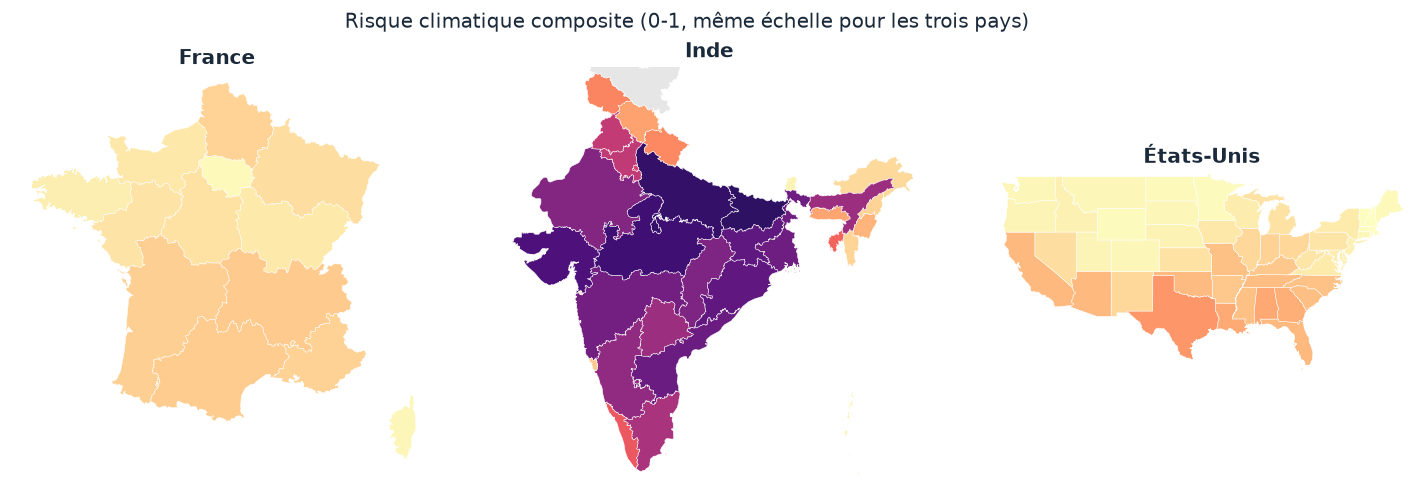

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
bounds = {"FRA": (-5.5, 9.8, 41, 51.3), "IND": (67.5, 97.5, 7.5, 35.5), "USA": (-125.5, -66.5, 24, 49.5)}
for ax, iso3 in zip(axes, ["FRA", "IND", "USA"]):
    regions[regions["iso3"] == iso3].plot(column="risk_equal", cmap="magma_r", vmin=0, vmax=1,
                                          ax=ax, edgecolor="white", linewidth=0.3,
                                          missing_kwds={"color": "#e6e6e6"})
    ax.set_xlim(*bounds[iso3][:2]); ax.set_ylim(*bounds[iso3][2:])
    ax.set_title(COUNTRY_NAMES[iso3]); ax.axis("off")
fig.suptitle("Risque climatique composite (0-1, même échelle pour les trois pays)")
plt.show()

Sur une échelle commune, le top 10 est entièrement indien :

In [8]:
regions.nlargest(10, "risk_equal")[
    ["region_name", "iso3", "hazard_equal", "exposure_score", "vulnerability", "risk_equal"]
]

,region_name,iso3,hazard_equal,exposure_score,vulnerability,risk_equal
82,Bihār,IND,0.849,0.981,0.990,0.825
73,Uttar Pradesh,IND,0.844,1.000,0.965,0.815
96,Madhya Pradesh,IND,0.860,0.962,0.949,0.786
76,Gujarāt,IND,0.913,0.933,0.889,0.757
90,Jhārkhand,IND,0.830,0.876,0.980,0.713
81,Odisha,IND,0.814,0.905,0.965,0.711
86,Andhra Pradesh,IND,0.833,0.914,0.899,0.685
80,West Bengal,IND,0.763,0.971,0.909,0.674
70,Mahārāshtra,IND,0.871,0.990,0.773,0.667
75,Chhattīsgarh,IND,0.833,0.829,0.919,0.635


Au sein de chaque pays (colonne `rank_in_country`), les 3 premières régions sont :

In [9]:
(regions[regions["rank_in_country"] <= 3]
 .sort_values(["iso3", "rank_in_country"])
 [["iso3", "rank_in_country", "region_name", "risk_equal"]])

,iso3,rank_in_country,region_name,risk_equal
10,FRA,1.0,Auvergne-Rhône-Alpes,0.111
9,FRA,2.0,Occitanie,0.109
8,FRA,3.0,Nouvelle-Aquitaine,0.102
82,IND,1.0,Bihār,0.825
73,IND,2.0,Uttar Pradesh,0.815
96,IND,3.0,Madhya Pradesh,0.786
28,USA,1.0,Texas,0.223
30,USA,2.0,Alabama,0.182
18,USA,3.0,Louisiana,0.177


## 5. H1 - Plus d'aléa, moins de développement ?

Corrélation de rang de Spearman entre l'aléa et le SHDI, sur toutes les régions puis pays par
pays. Nous appelons `hazard_development_test` de `src/cro/analysis/tests.py`.

In [10]:
h1 = pd.DataFrame(
    [hazard_development_test(regions, "ALL")]
    + [hazard_development_test(group, iso3) for iso3, group in regions.groupby("iso3")]
)
h1

,group,n_regions,spearman_rho,p_value,median_shdi_high_hazard,median_shdi_low_hazard
0,ALL,99,-0.589,1.387e-10,0.786,0.936
1,FRA,13,0.176,5.656e-01,0.908,0.898
2,IND,35,-0.483,3.266e-03,0.686,0.737
3,USA,51,-0.481,3.540e-04,0.923,0.942


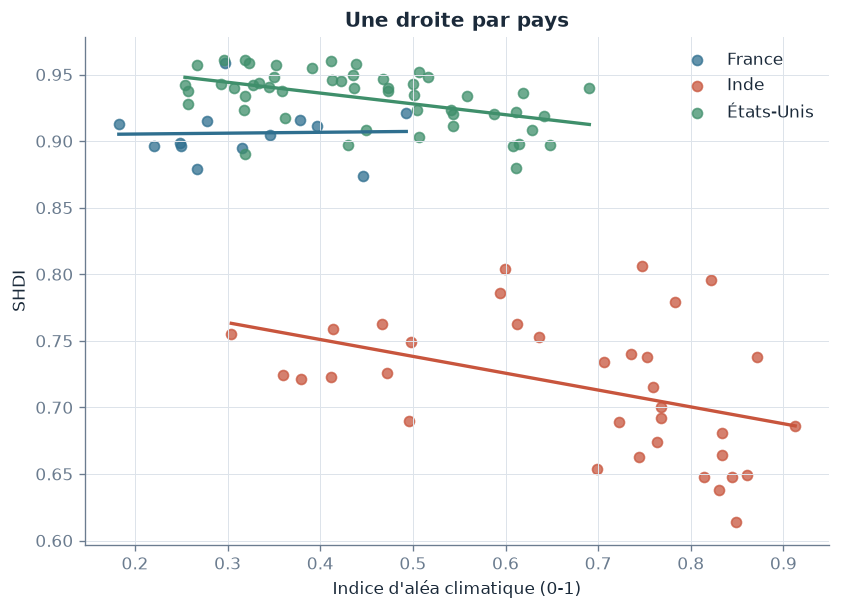

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for iso3, group in regions.dropna(subset=["shdi"]).groupby("iso3"):
    color = theme.COUNTRY_COLORS[iso3]
    ax.scatter(group["hazard_equal"], group["shdi"], color=color, alpha=0.75, label=COUNTRY_NAMES[iso3])
    slope, intercept = np.polyfit(group["hazard_equal"], group["shdi"], 1)
    x = np.linspace(group["hazard_equal"].min(), group["hazard_equal"].max(), 20)
    ax.plot(x, intercept + slope * x, color=color, linewidth=2)
ax.set_xlabel("Indice d'aléa climatique (0-1)"); ax.set_ylabel("SHDI"); ax.legend()
ax.set_title("Une droite par pays")
plt.show()

**Lecture.** Sur toutes les régions, la corrélation est forte (environ −0,59), mais les points
forment trois groupes. En Inde et aux États-Unis, la corrélation est plus faible (environ −0,48)
et en France il n'y a pas de lien net. Une grande partie de H1 vient donc de la différence entre
l'Inde et les deux autres pays.

## 6. H2 - Est-ce encore vrai à l'intérieur de chaque pays ?

Deux régressions linéaires (fonctions dans `src/cro/analysis/regression.py`) :

- **M1 :** `shdi ~ hazard_equal`
- **M2 :** `shdi ~ hazard_equal + C(iso3)` - une indicatrice par pays, de sorte que seules les
  différences entre régions d'un *même* pays sont utilisées.

In [12]:
model_data = regions.dropna(subset=["shdi", "hazard_equal"])
pd.DataFrame([fit_model(model_data, formula, name) for name, formula in MODELS])

,model,term,beta,std_error,p_value,ci_low,ci_high,n_obs,r_squared
0,M1 all regions,hazard_equal,-0.392,0.036,1.620e-27,-0.463,-0.321,99,0.479
1,M2 country effects,hazard_equal,-0.101,0.023,8.743e-06,-0.145,-0.056,99,0.914


In [13]:
country_slopes(model_data)

,iso3,n_regions,slope,std_error,p_value,ci_low,ci_high,r_squared
0,FRA,13,0.007,0.075,9.298e-01,-0.140,0.154,8.036e-04
1,IND,35,-0.127,0.040,1.365e-03,-0.204,-0.049,1.792e-01
2,USA,51,-0.081,0.022,2.724e-04,-0.125,-0.037,2.331e-01


**Lecture.** Le coefficient de l'aléa passe d'environ −0,39 (M1) à environ −0,10 (M2) : à peu
près les trois quarts du lien se situent entre les pays, mais un lien plus faible et significatif
subsiste à l'intérieur des pays. Il est net en Inde et aux États-Unis, absent en France (seulement
13 régions).

## 7. H3 - Le classement est-il stable ?

Nous comparons l'indice principal avec deux autres versions : la moyenne simple des trois scores
(`additive`) et une version sans la population (`per_person` = aléa × vulnérabilité).

In [14]:
versions = pd.concat([
    regions[["region_id", f"rank_{v}"]].rename(columns={f"rank_{v}": "rank"}).assign(version=v)
    for v in ["equal", "additive", "per_person"]
])
test_rank_stability(versions.dropna(subset=["rank"]))

,version_a,version_b,n_regions,spearman_rho,same_in_top10
0,additive,equal,99,0.970,10
1,additive,per_person,99,0.893,9
2,equal,per_person,99,0.863,9


**Lecture.** Les classements sont fortement corrélés et au moins 9 des 10 premières régions sont
les mêmes dans chaque paire. Même sans la population, les mêmes États indiens arrivent en tête :
le résultat n'est pas seulement un effet de taille.

## 8. Conclusion

| Hypothèse | Résultat |
|---|---|
| H1 - plus d'aléa, SHDI plus faible | Oui sur toutes les régions ; plus faible à l'intérieur des pays |
| H2 - encore vrai à l'intérieur des pays | Oui en Inde et aux États-Unis, avec un effet plus petit ; pas en France |
| H3 - classement stable | Oui |

Ce sont des **associations, pas des causes**. Les régions voisines se ressemblent, donc les
p-valeurs sont probablement trop petites ; un modèle spatial serait l'étape suivante. La méthode
complète, les références et toutes les limites sont dans le rapport :
`outputs/report/report.fr.html` (français) et `outputs/report/report.html` (anglais).